In [7]:
import os

import numpy as np  # import numpy to do the fft
import matplotlib.pyplot as plt
from scipy.io import wavfile  # import the libraries for reading sound files
from scipy.fft import fft, fftfreq


In [8]:
SAMPLE_RATE = 44100  # Hertz
DURATION = 5  # Seconds

# Number of samples in normalized_tone
N = SAMPLE_RATE * DURATION

FREQS = [5, 10, 15]
TOL = 0.05

AUDIO_FILE = "synt_test.wav"

figure_width = 7  # inches
figure_height = 3.5  # inches

In [9]:
def generate_sine_wave(freq, sample_rate, duration):
    x = np.linspace(0, duration, sample_rate * duration, endpoint=False)
    frequencies = x * freq
    # 2pi because np.sin takes radians
    y = np.sin((2 * np.pi) * frequencies)
    return x, y


for freq in FREQS:
    _, tone = generate_sine_wave(freq * 1e3, SAMPLE_RATE, DURATION)
    normalized_tone = np.int16((tone / tone.max()) * 32767)

    # Remember SAMPLE_RATE = 44100 Hz is our playback rate
    wavfile.write(os.path.join("samples", f"sample_{freq}_kHz.wav"), SAMPLE_RATE, normalized_tone)

In [23]:
def test_auido(pth, target_freq):
    # Load the file -get sampling_frequency and the data array
    sampling_freq, sound_data = wavfile.read(pth)

    # Determine the maximum values
    max_value = np.max(np.abs(sound_data))
    print(f'Max Value is {max_value}')
    print(f'Sampling frequency is', sampling_freq, 'Hz')
    # Use max_value and normalize sound data to get values between -1 & +1
    sound_data = sound_data/max_value
    # Lets just take a single audio channel (mono) even if it is stereo
    if len(sound_data.shape) == 1:
        s1 = sound_data
    else:
        s1 = sound_data[:, 0]

    # Get time domain representation of the sound pressure waves
    timeArray = np.arange(0, s1.shape[0], 1.0)
    timeArray = timeArray / sampling_freq  # Second
    timeArray = timeArray * 1000  # Scale to milliseconds

    # Plot the sound signal in time domain
    plt.figure(figsize=(figure_width, figure_height))
    plt.plot(timeArray[:1000], sound_data[:1000], color='b')

    plt.xlabel('Time [ms]')
    plt.ylabel('Amplitude', fontsize=12)
    plt.grid()
    plt.tight_layout()

    # ================ Fast Fourier Transform ==============================
    # Calculate length of the signal
    N = len(s1)
    Time_period = 1/sampling_freq

    yf = fft(s1)  # Perform the Fourier transform
    xf = fftfreq(N, Time_period)#[:N//2]  # calculate the frequencies in the center of each bin

    # Calculate the magnitude of the FFT result
    magnitude = np.abs(yf)
    # Find the index of the maximum magnitude
    max_magnitude_index = np.argmax(magnitude)

    # Calculate the magnitude of the FFT result
    magnitude = np.abs(yf)
    # Find the index of the maximum magnitude
    max_magnitude_index = np.argmax(magnitude)

    # Calculate the corresponding frequency with respect to index and sampling rate
    max_frequency = max_magnitude_index * sampling_freq / len(s1)
    print("Frequency with highest FFT magnitude:", max_frequency, "Hz")
    print("The highest FFT magnitude:", magnitude[max_magnitude_index])

    assert abs(max_frequency - target_freq) < target_freq * TOL, \
        f"Max frequency not equal to target value: {max_frequency} VS {target_freq}"

    # ===========================Frequency domain plot ======================
    plt.figure(figsize=(figure_width, figure_height))
    # Typically only the FFT corresponding to positive frequencies is plotted
    plt.plot(xf, magnitude, color='r')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Magnitude')
    plt.xlim(4000, 16000)
    plt.grid()
    plt.tight_layout()
    plt.show()

5 kHz
Max Value is 32767
Sampling frequency is 44100 Hz
Frequency with highest FFT magnitude: 5000.0 Hz
The highest FFT magnitude: 110248.53234985449


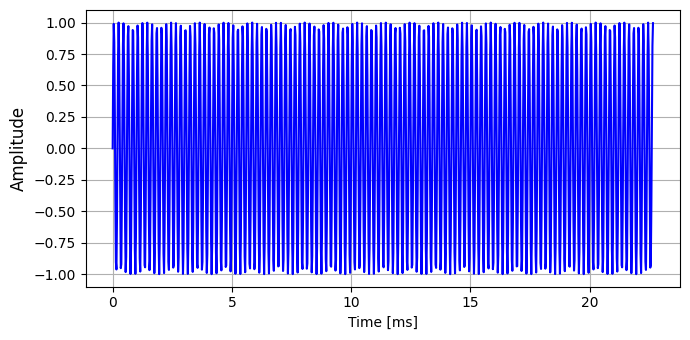

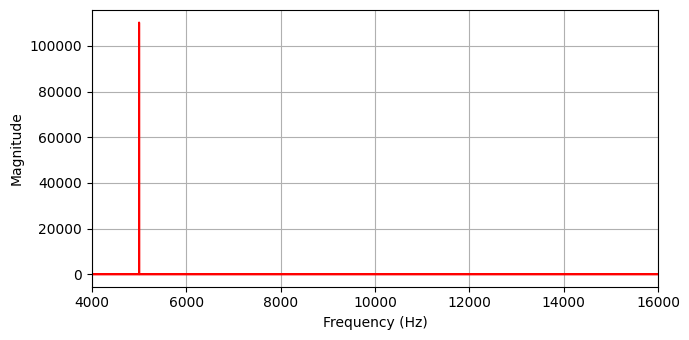

In [24]:
print("5 kHz")

test_auido("samples/sample_5_kHz.wav", 5 * 1e3)

15 kHz
Max Value is 32767
Sampling frequency is 44100 Hz
Frequency with highest FFT magnitude: 15000.0 Hz
The highest FFT magnitude: 110254.20421158792


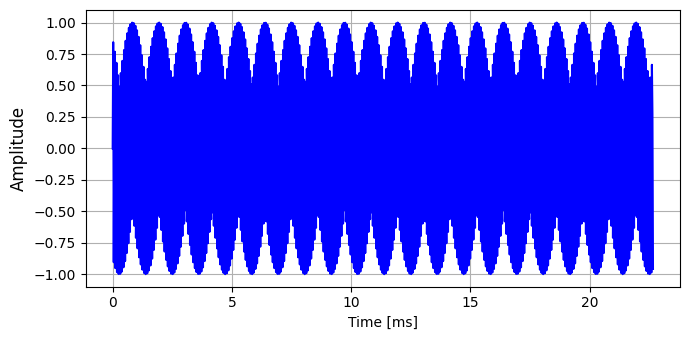

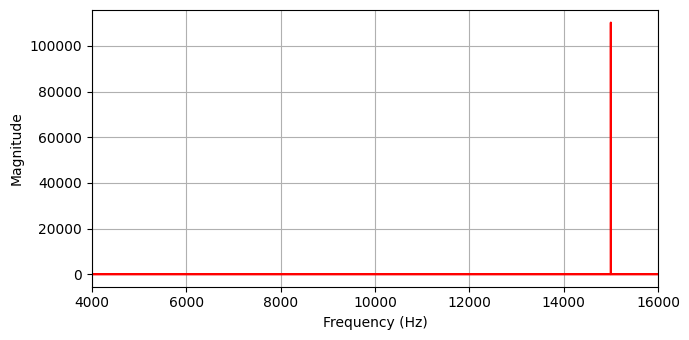

In [25]:
print("15 kHz")

test_auido("samples/sample_15_kHz.wav", 15 * 1e3)

5 kHz
Max Value is 8395
Sampling frequency is 48000 Hz
Frequency with highest FFT magnitude: 4999.855990783411 Hz
The highest FFT magnitude: 49520.79086827642


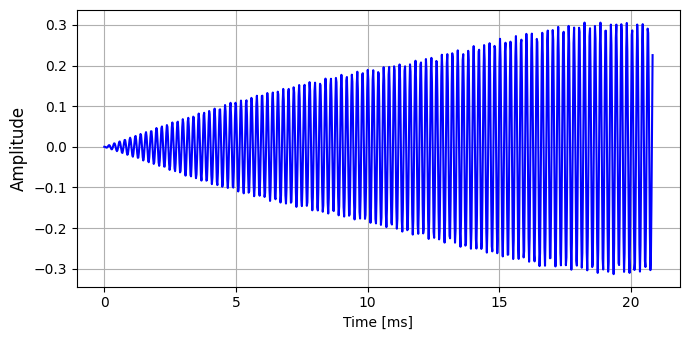

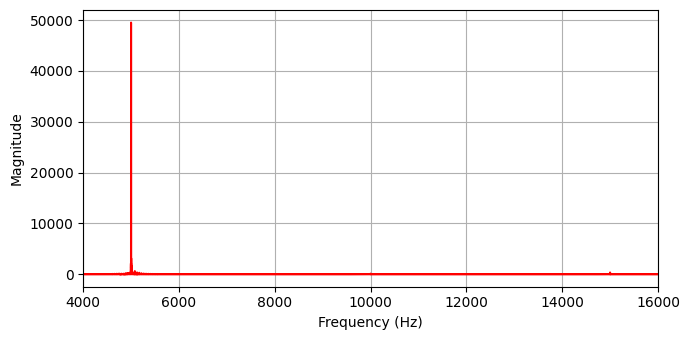

In [26]:
print("5 kHz")

test_auido("records/5.wav", 5 * 1e3)

10 kHz
Max Value is 5567
Sampling frequency is 48000 Hz
Frequency with highest FFT magnitude: 9999.715424018214 Hz
The highest FFT magnitude: 54950.021991416914


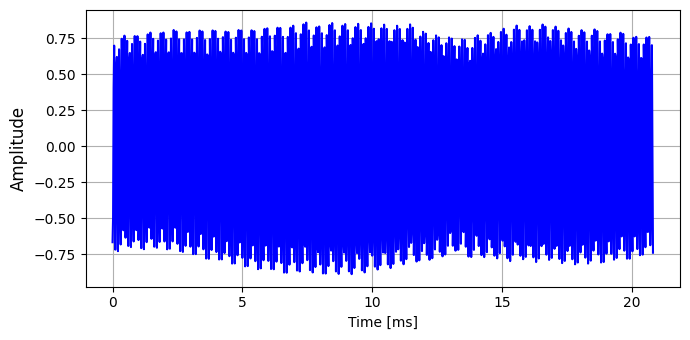

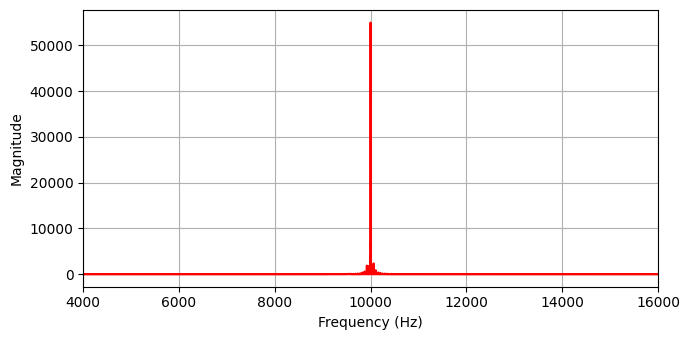

In [27]:
print("10 kHz")

test_auido("records/10.wav", 10 * 1e3)

15 kHz
Max Value is 5105
Sampling frequency is 48000 Hz
Frequency with highest FFT magnitude: 14999.781341107871 Hz
The highest FFT magnitude: 66934.86254672548


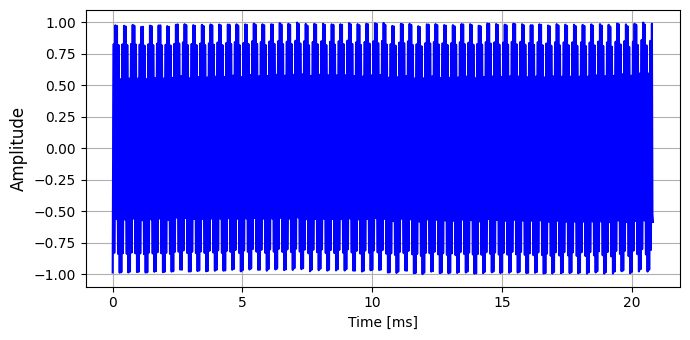

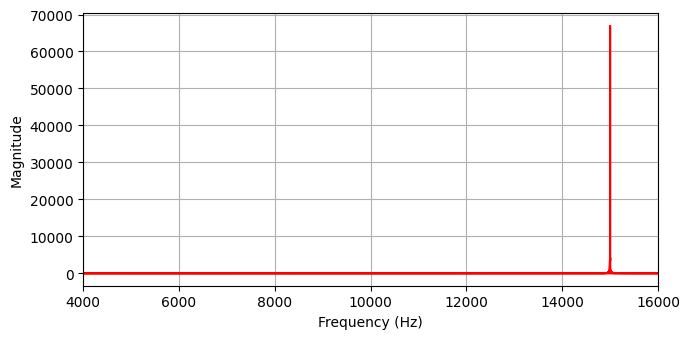

In [28]:
print("15 kHz")

test_auido("records/15.wav", 15 * 1e3)